In [1]:
%load_ext cuml.accel

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN



In [3]:
# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)
path+="/creditcard.csv"

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [4]:
df = pd.read_csv(path)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# EDA

In [5]:
display(df.info())
display(df.describe())
display(df.shape)
display(df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

None

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


(284807, 31)

np.int64(0)

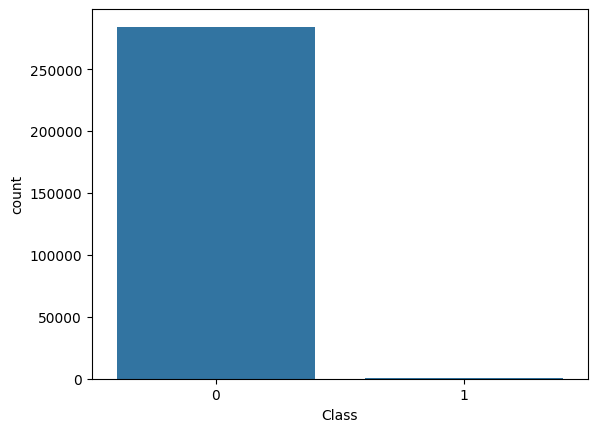

Persentase: Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [6]:
# Class distribution diagram
sns.countplot(x='Class', data=df)
plt.show()
print("Persentase:",df['Class'].value_counts(normalize=True)*100)

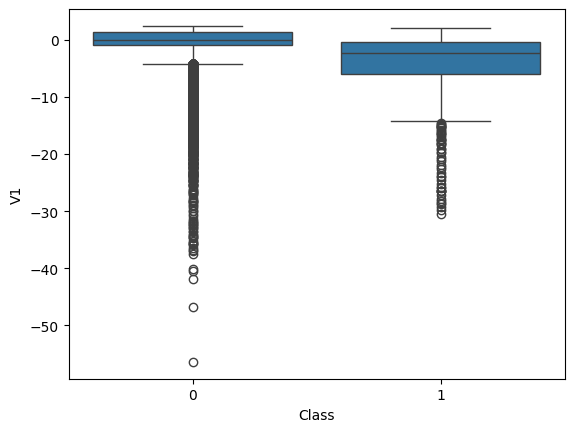

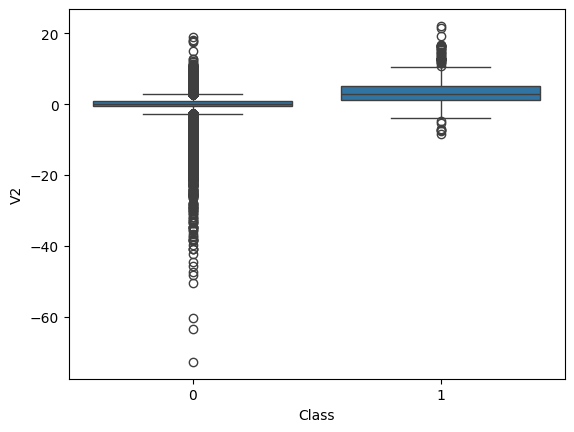

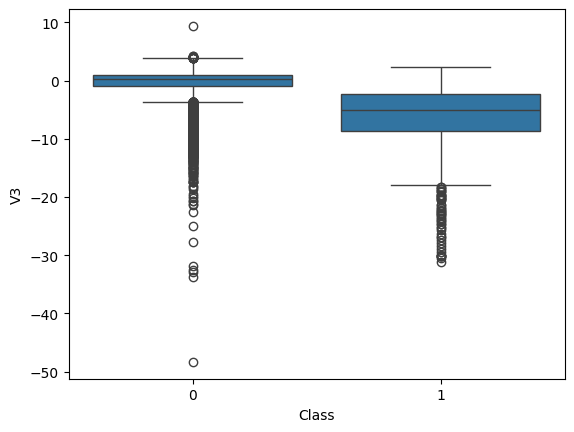

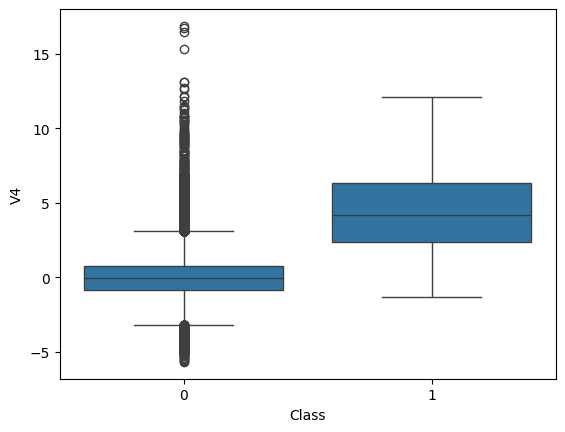

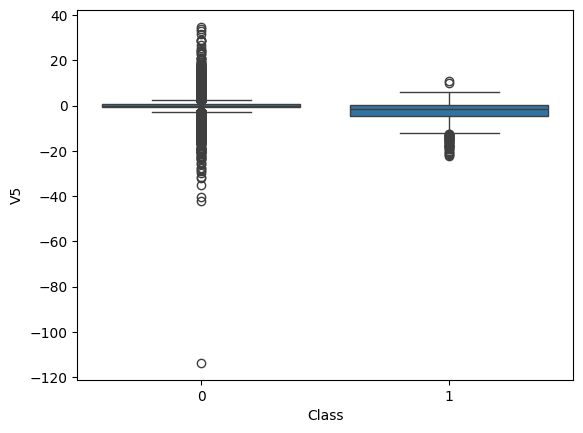

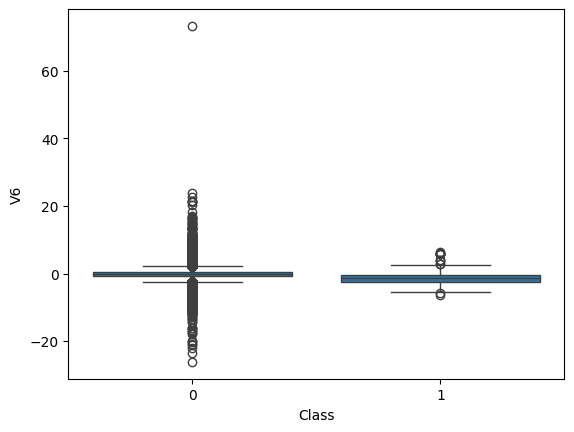

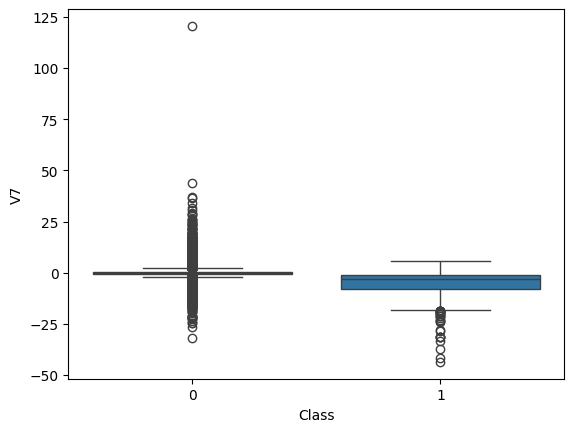

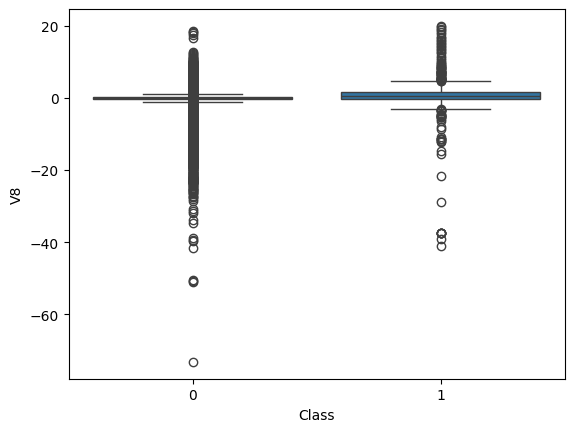

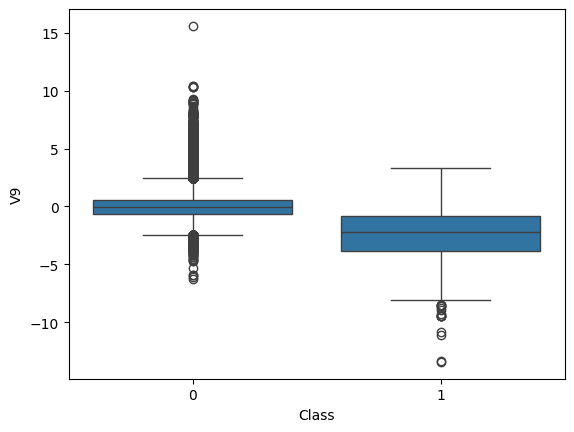

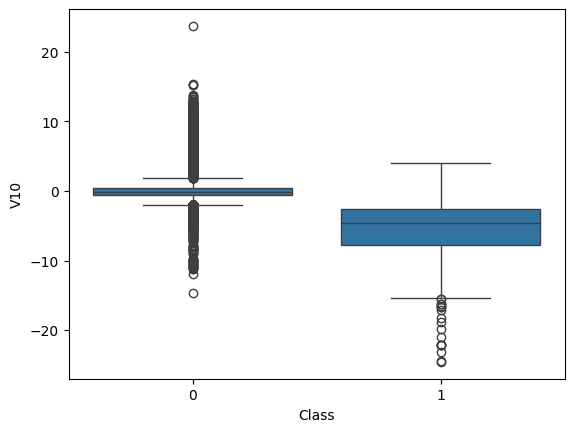

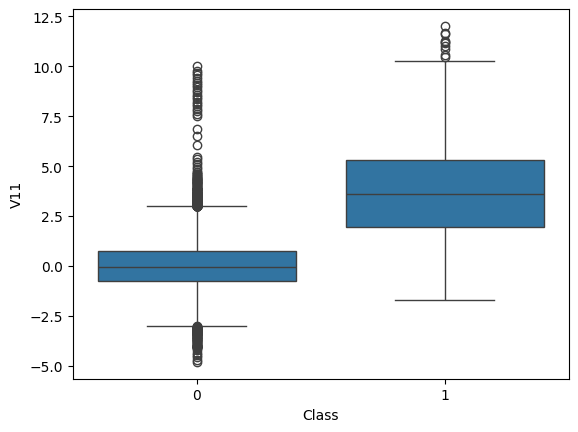

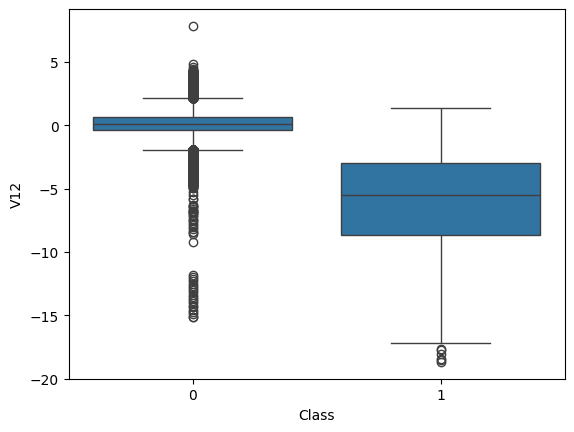

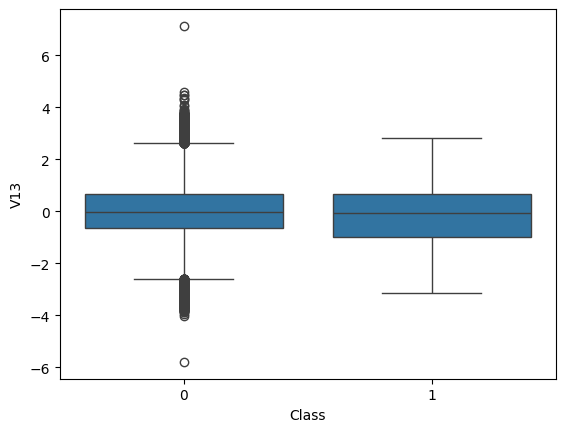

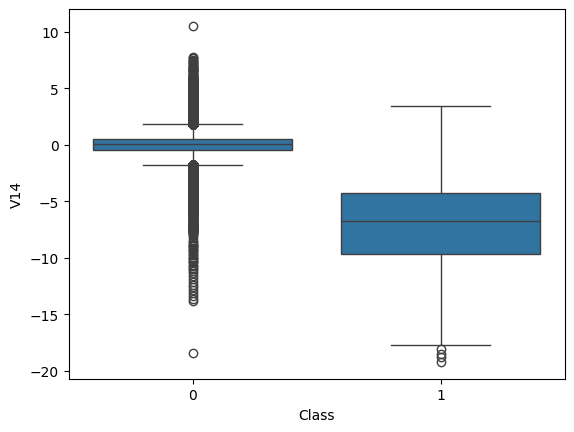

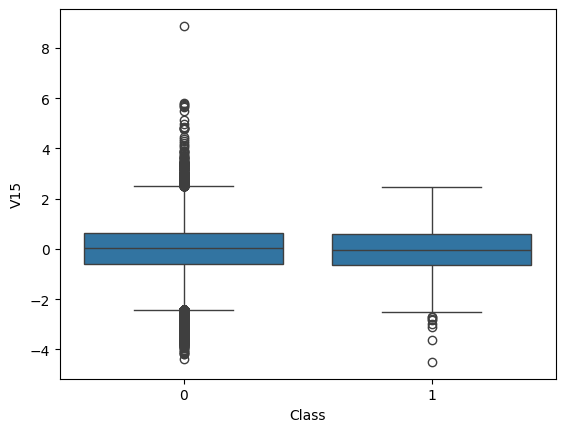

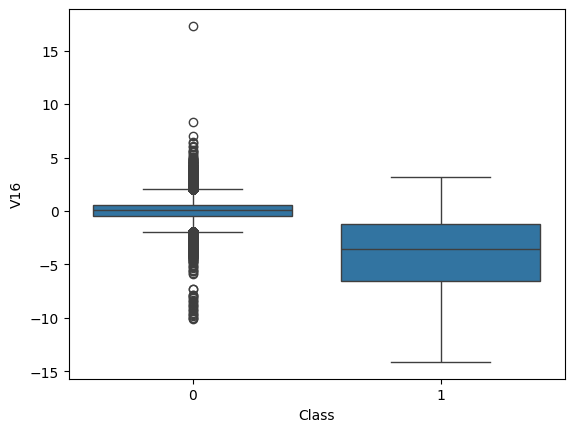

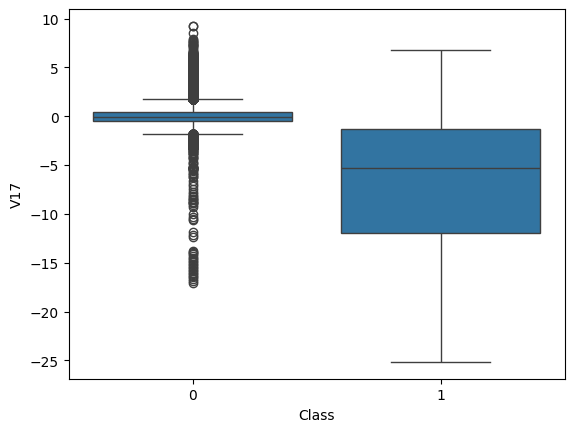

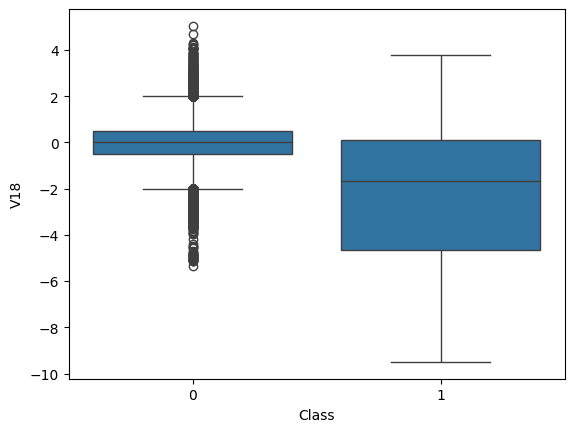

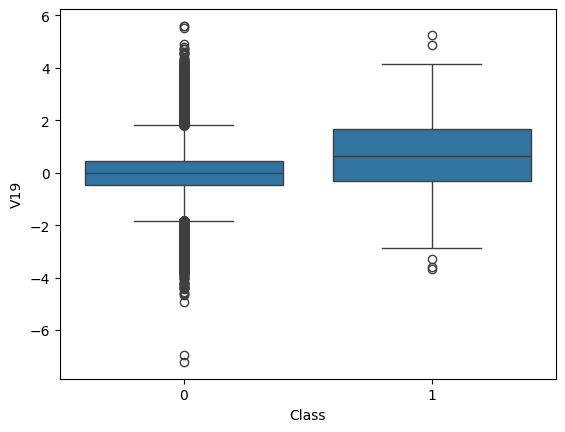

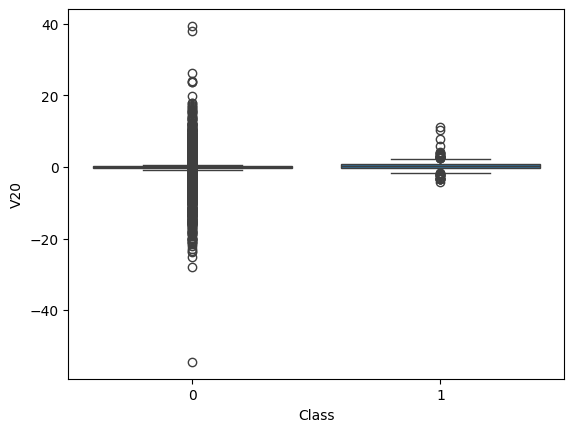

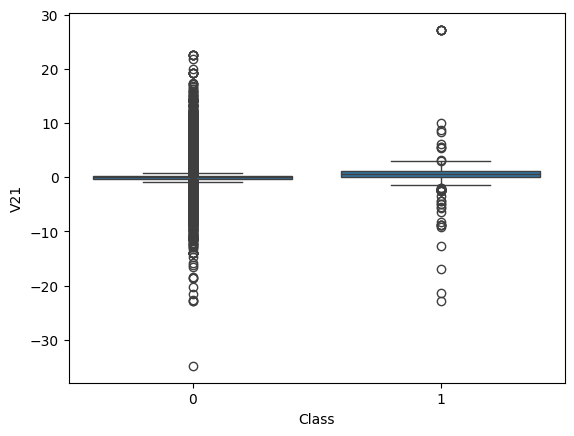

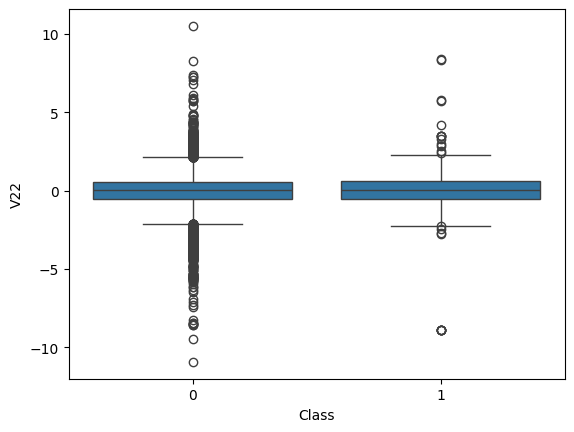

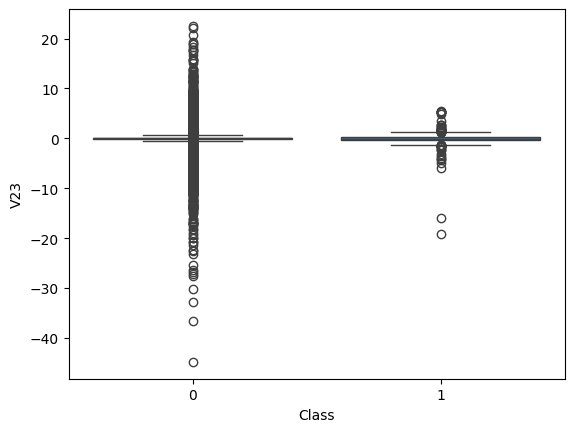

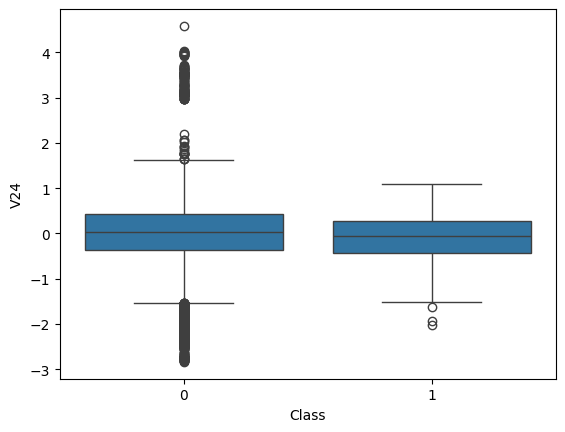

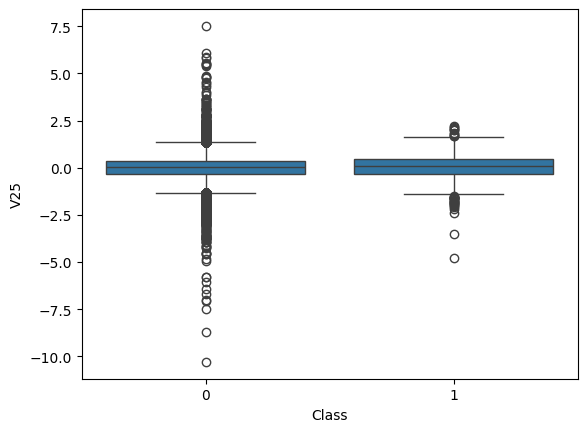

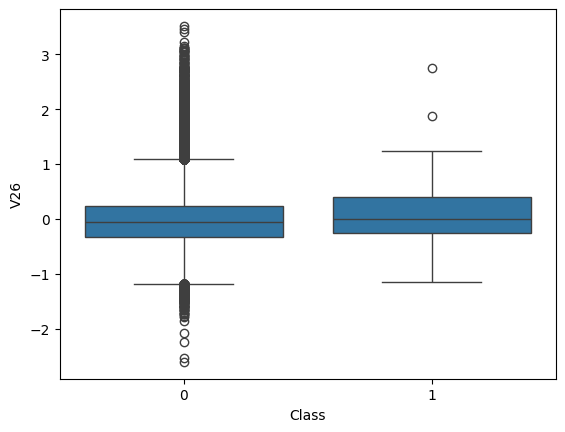

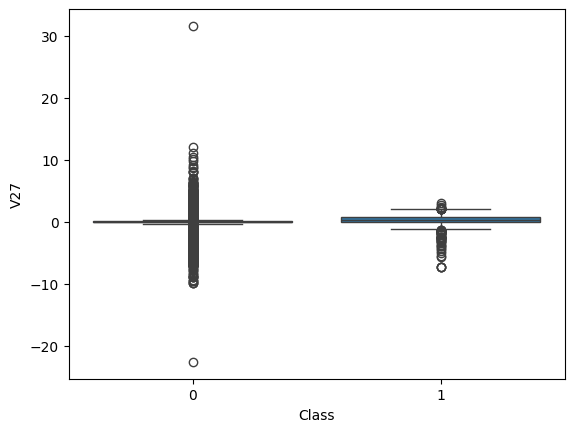

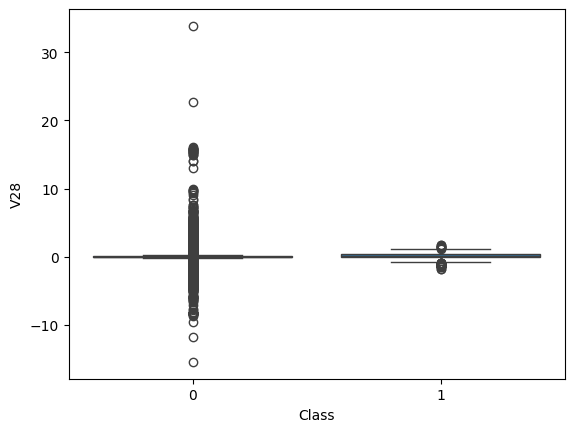

In [7]:
# cek V1 - v28 dengan box plot
selected = df.columns[df.columns.str.contains('V')]
for i in selected:
    sns.boxplot(x='Class', y=i, data=df)
    plt.show()


In [8]:
#Outlier analysis
features = [f"V{i}" for i in range(1, 29)]

results = []

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = (df[col] < lower) | (df[col] > upper)

    results.append({
        "Feature": col,
        "Total Outlier": outlier.sum(),
        "Normal Outlier": (outlier & (df["Class"] == 0)).sum(),
        "Fraud Outlier": (outlier & (df["Class"] == 1)).sum(),
        "Normal Outlier (%)": outlier[df["Class"] == 0].mean() * 100,
        "Fraud Outlier (%)": outlier[df["Class"] == 1].mean() * 100
    })

outlier_df = pd.DataFrame(results)

display(outlier_df.round(2))

,Feature,Total Outlier,Normal Outlier,Fraud Outlier,Normal Outlier (%),Fraud Outlier (%)
0,V1,7062,6888,174,2.42,35.37
1,V2,13526,13280,246,4.67,50.00
2,V3,3363,3051,312,1.07,63.41
3,V4,11148,10830,318,3.81,64.63
4,V5,12295,12087,208,4.25,42.28
5,V6,22965,22828,137,8.03,27.85
6,V7,8948,8647,301,3.04,61.18
7,V8,24134,23887,247,8.40,50.20
8,V9,8283,8060,223,2.83,45.33
9,V10,9496,9097,399,3.20,81.10


## Outlier tidak perlu dihapus karena penting

# Preprocessing

In [9]:
# drop duplicates
if df.duplicated().sum():
  df.drop_duplicates(inplace=True)

In [10]:
X = df.drop('Class', axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
# Kumpulan metode untuk dicoba
methods = {
    "None":None,
    "RandomOverSampler":RandomOverSampler(random_state=42),
    "RandomUnderSampler":RandomUnderSampler(random_state=42),
    "SMOTE":SMOTE(random_state=42), # Oversampler
    "ADASYN":ADASYN(random_state=42), # Oversampler
    "SMOTEENN":SMOTEENN(random_state=42) # Hybrid
}

# Model

In [12]:
eval = []

In [13]:
eval = []
roc_results = {}
cm_results = {}

for name, func in methods.items():
    if name != "None":
        X_resampled, y_resampled = func.fit_resample(X_train, y_train)
    else:
        X_resampled, y_resampled = X_train, y_train

    model = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_resampled, y_resampled)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    roc_results[name] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc
    }

    # Confusion Matrix
    cm_results[name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    # Evaluation Metrics
    eval.append({
        "Sampling": name,
        "Train Samples": len(y_resampled),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": auc,
        "PR-AUC": average_precision_score(
            y_test, y_prob
        )
    })

    print(name, "Done")

results_df = pd.DataFrame(eval)

display(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [09:32:34] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


None Done


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [09:32:40] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


RandomOverSampler Done


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [09:32:41] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


...

SMOTE Done


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [09:32:54] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


ADASYN Done
SMOTEENN Done


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [09:33:11] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


,Sampling,Train Samples,Precision,Recall,F1,ROC-AUC,PR-AUC
0,None,226980,0.9577,0.7158,0.8193,0.9385,0.8036
1,RandomOverSampler,453204,0.9718,0.7263,0.8313,0.9548,0.8108
2,RandomUnderSampler,756,0.0817,0.8737,0.1494,0.9732,0.6956
3,SMOTE,453204,0.9136,0.7789,0.8409,0.9518,0.8065
4,ADASYN,453348,0.9136,0.7789,0.8409,0.9666,0.8169
5,SMOTEENN,314790,0.9012,0.7684,0.8295,0.9512,0.7882


# Evaluation

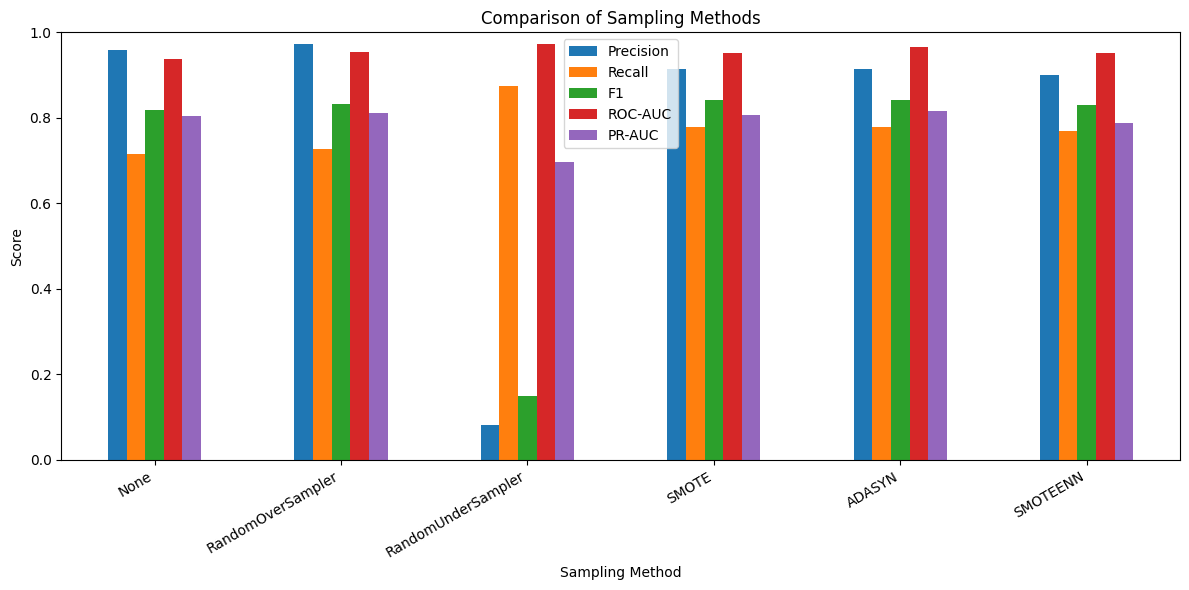

In [14]:
metrics = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

results_df.set_index("Sampling")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Sampling Methods")
plt.ylabel("Score")
plt.xlabel("Sampling Method")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

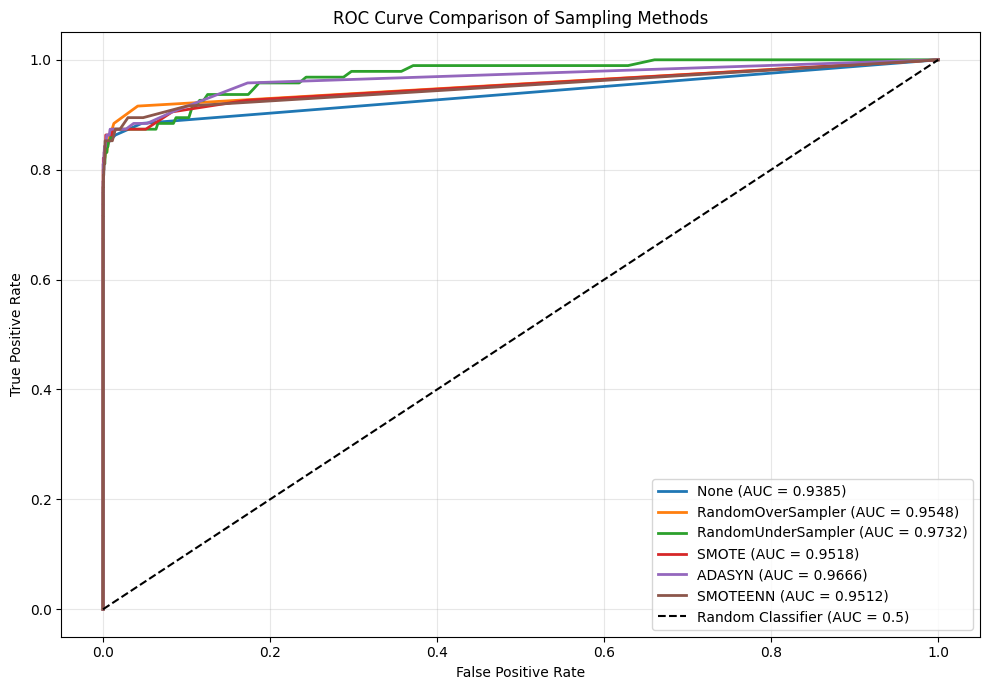

In [15]:
plt.figure(figsize=(10, 7))

for name, data in roc_results.items():
    plt.plot(
        data["fpr"],
        data["tpr"],
        label=f'{name} (AUC = {data["auc"]:.4f})',
        linewidth=2
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Sampling Methods")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

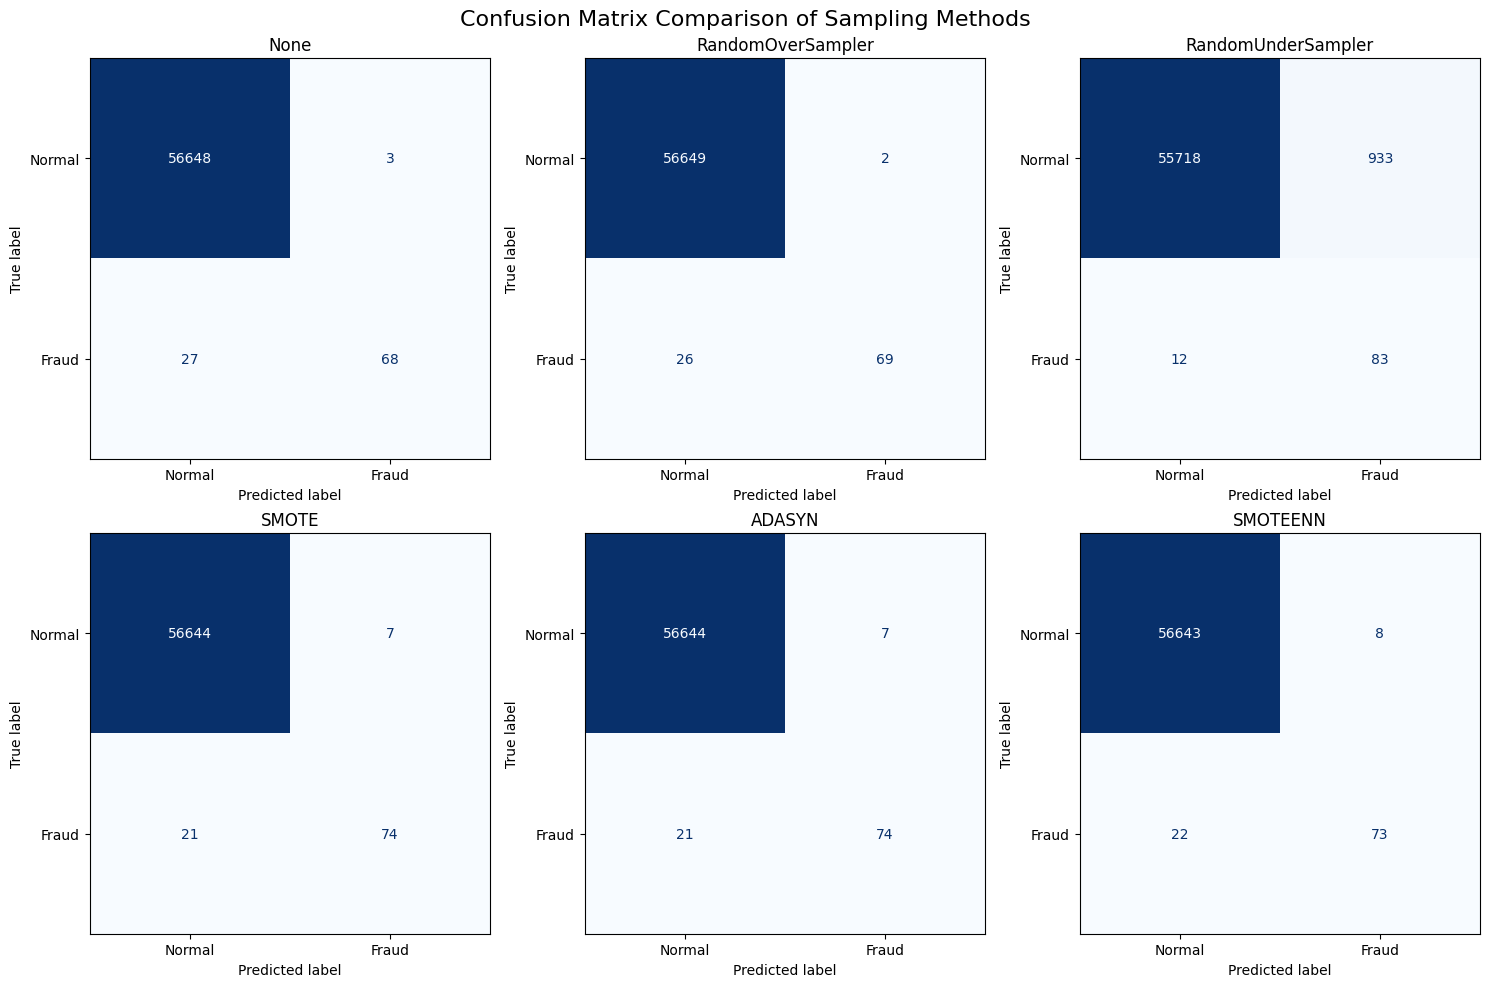

In [16]:
n = len(cm_results)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = np.array(axes).flatten()

for ax, (name, cm) in zip(axes, cm_results.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name, fontsize=12)

for ax in axes[n:]:
    ax.axis("off")

plt.suptitle(
    "Confusion Matrix Comparison of Sampling Methods",
    fontsize=16
)

plt.tight_layout()
plt.show()